In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería (notebooks/colecciones/<coleccion>/ -> ../../../src)
sys.path.append(os.path.abspath('../../../src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Un compañero ha redactado el cuadro de prelaciones inmediatas del proyecto que se muestra a continuación. Antes de dibujar el grafo conviene revisarlo: sospechamos que contiene prelaciones redundantes (ya implicadas por otras).

In [3]:
pregunta_1 = "1. Identifique las prelaciones redundantes y escriba el cuadro de prelaciones inmediatas mínimo.  "
pregunta_2 = "2. Construya el cuadro de prelaciones expandido (matriz de prelaciones inmediatas) y, a partir de él, indique las actividades iniciales y finales del proyecto.  "
pregunta_3 = "3. Construya el cuadro de ancestros (prelaciones transitivas) y compruebe que las prelaciones redundantes del apartado anterior aparecen en él.  "
pregunta_4 = "4. Dibuje el grafo PERT del proyecto y compruebe sobre él el cuadro de ancestros.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Identifique las prelaciones redundantes y escriba el cuadro de prelaciones inmediatas mínimo.  

2. Construya el cuadro de prelaciones expandido (matriz de prelaciones inmediatas) y, a partir de él, indique las actividades iniciales y finales del proyecto.  

3. Construya el cuadro de ancestros (prelaciones transitivas) y compruebe que las prelaciones redundantes del apartado anterior aparecen en él.  

4. Dibuje el grafo PERT del proyecto y compruebe sobre él el cuadro de ancestros.  

In [4]:
#| tbl-cap: "Cuadro de prelaciones tal y como lo recibimos"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor
    ('G'     , 'F'        ),
    ('I'     , 'D,F,H'    ),
    ('J'     , 'H,I'      ),
    ('F'     , 'E'        ),
    ('A'     , '---'      ),
    ('H'     , 'C,E'      ),
    ('D'     , 'C'        ),
    ('E'     , 'A,B,C'    ),
    ('B'     , '---'      ),
    ('C'     , '---'      ),
], columns=['activity', 'predecessor']).set_index('activity')
datos_enunciado

,predecessor
activity,
G,F
I,"D,F,H"
J,"H,I"
F,E
A,---
H,"C,E"
D,C
E,"A,B,C"
B,---


# Resolución

In [5]:
prelaciones_dadas = {act: set(p.strip() for p in fila.split(',') if p.strip() and p.strip() != '---')
                     for act, fila in datos_enunciado['predecessor'].items()}
G = nx.DiGraph()
G.add_nodes_from(prelaciones_dadas)
G.add_edges_from((p, a) for a, ps in prelaciones_dadas.items() for p in ps)

## Apartado 1

In [6]:
display(Markdown(pregunta_1))

1. Identifique las prelaciones redundantes y escriba el cuadro de prelaciones inmediatas mínimo.  

Una prelación «p precede a a» es redundante cuando p es antecesora de alguna otra predecesora inmediata de a: la relación ya está garantizada por transitividad. La reducción transitiva del grafo de prelaciones conserva exactamente las no redundantes.

In [7]:
reducido = nx.transitive_reduction(G)
redundantes = sorted(set(G.edges) - set(reducido.edges))
for p, a in redundantes:
    via = sorted(q for q in prelaciones_dadas[a] if q != p and p in nx.ancestors(G, q))
    print(f'{p} → {a} es redundante: {p} ya precede a {", ".join(via)}, que precede(n) a {a}')

C → H es redundante: C ya precede a E, que precede(n) a H
H → J es redundante: H ya precede a I, que precede(n) a J


In [8]:
#| tbl-cap: "Cuadro de prelaciones inmediatas mínimo"
#| label: tbl-prelacionesMinimas
prelaciones_minimas = {a: ','.join(sorted(reducido.predecessors(a))) or '---' for a in sorted(G.nodes)}
datos_proyecto = pd.DataFrame({'predecessor': pd.Series(prelaciones_minimas)})
datos_proyecto.index.name = 'activity'
datos_proyecto

,predecessor
activity,
A,---
B,---
C,---
D,C
E,"A,B,C"
F,E
G,F
H,E
I,"D,F,H"


La librería hace esta misma depuración al construir la tabla de prelaciones, por lo que podemos usarla como comprobación:

In [9]:
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
pd.Series({a: ','.join(sorted(ps)) or '---' for a, ps in prelaciones.immediate_predecessor.items()}).to_frame('predecessor')

,predecessor
A,---
B,---
C,---
D,C
E,"A,B,C"
F,E
G,F
H,E
I,"D,F,H"
J,I


## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Construya el cuadro de prelaciones expandido (matriz de prelaciones inmediatas) y, a partir de él, indique las actividades iniciales y finales del proyecto.  

En el cuadro expandido cada fila indica las predecesoras inmediatas de una actividad y cada columna sus sucesoras inmediatas. Una fila vacía señala una actividad inicial; una columna vacía, una actividad final.

In [11]:
#| tbl-cap: "Cuadro de prelaciones expandido"
#| label: tbl-prelacionesExpandido
prelaciones.display_immediate_linkage_matrix()

,A,B,C,D,E,F,G,H,I,J
activities,,,,,,,,,,
A,,,,,,,,,,
B,,,,,,,,,,
C,,,,,,,,,,
D,,,True,,,,,,,
E,True,True,True,,,,,,,
F,,,,,True,,,,,
G,,,,,,True,,,,
H,,,,,True,,,,,
I,,,,True,,True,,True,,


In [12]:
print('Actividades iniciales:', ', '.join(sorted(prelaciones.start_activities)))
print('Actividades finales:  ', ', '.join(sorted(prelaciones.end_activities)))

Actividades iniciales: A, B, C
Actividades finales:   G, J


## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. Construya el cuadro de ancestros (prelaciones transitivas) y compruebe que las prelaciones redundantes del apartado anterior aparecen en él.  

In [14]:
proyecto = prelaciones.create_project()

In [15]:
#| tbl-cap: "Cuadro de ancestros (prelaciones transitivas)"
#| label: tbl-ancestros
proyecto.distant_predecessor(format='DataFrame')

,predecessors
A,----
B,----
C,----
D,C
E,"A, B, C"
F,"A, B, C, E"
G,"A, B, C, E, F"
H,"A, B, C, E"
I,"A, B, C, D, E, F, H"
J,"A, B, C, D, E, F, H, I"


In [16]:
ancestros = proyecto.distant_predecessor()
for p, a in redundantes:
    print(f'{p} ∈ ancestros({a}): {p in ancestros[a]}')

C ∈ ancestros(H): True
H ∈ ancestros(J): True


## Apartado 4

In [17]:
display(Markdown(pregunta_4))

4. Dibuje el grafo PERT del proyecto y compruebe sobre él el cuadro de ancestros.  

Las actividades ficticias (discontinuas) del grafo transmiten precisamente las prelaciones que no pueden representarse compartiendo nodos. Siguiendo hacia atrás los arcos desde el final de cada actividad se recorren todos sus ancestros.

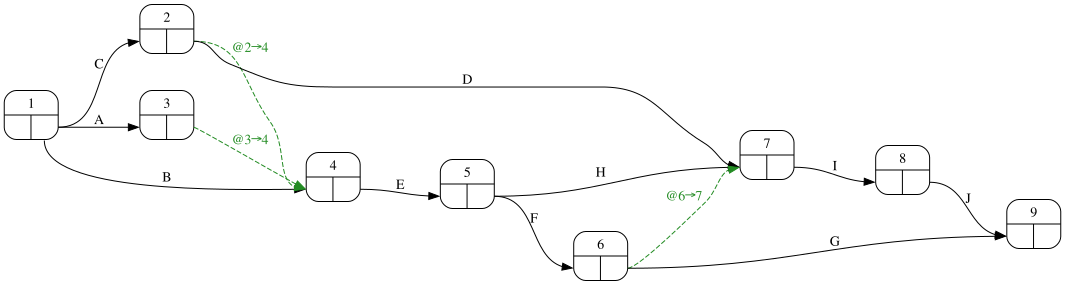

In [18]:
#| fig-cap: "Grafo PERT del proyecto"
#| label: fig-pert
proyecto.pert(durations=False, ranksep=1)